# 4.1 Modèle image : 85 mesures + XGBoost, Dataset 2 (extrait final, 60 000 images)

85 mesures par document, sans lire les mots : 70 sur les pixels (dont une grille 8 × 8 de la
quantité d'encre) et 15 de mise en page, tirées des boîtes des mots de l'OCR. Même découpage que le
modèle texte de référence.

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from outils_4 import ARTEFACTS_60K, ARTEFACTS_DATASET_1, load_corpus_60k, load_image_features

## 1. Les 85 mesures

Calculées une fois (2 minutes) puis enregistrées ; elles resservent en 4.5.2. Avec OpenCV : le seuillage d'Otsu sépare l'encre du fond, l'ouverture morphologique ne garde que les
traits longs.

In [2]:
def pixel_features(chemin):
    """70 mesures sur les pixels, sans OCR"""
    gris = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)
    hauteur, largeur = gris.shape
    # otsu : encre en blanc, fond en noir
    _, encre = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # on ne garde que les traits de plus de 40 px (lignes de tableau)
    lignes_h = cv2.morphologyEx(encre, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (40, 1)))
    lignes_v = cv2.morphologyEx(encre, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, 40)))
    mesures = {"mean_intensity": gris.mean() / 255, "std_intensity": gris.std() / 255, "aspect_ratio": largeur / hauteur,
               "ink_ratio": (encre > 0).mean(), "h_line_ratio": (lignes_h > 0).mean(), "v_line_ratio": (lignes_v > 0).mean()}
    # grille 8x8 : quantité d'encre dans chaque case
    bords_y = [i * (hauteur // 8) for i in range(8)] + [hauteur]
    bords_x = [j * (largeur // 8) for j in range(8)] + [largeur]
    for i in range(8):
        for j in range(8):
            mesures[f"grid_{i}_{j}"] = (encre[bords_y[i]:bords_y[i + 1], bords_x[j]:bords_x[j + 1]] > 0).mean()
    return mesures


def layout_features(boites, documents):
    """15 mesures de mise en page, calculées sur les boîtes des mots de l'OCR"""
    mots = boites[(boites["width"] > 0) & (boites["height"] > 0)]
    mots = mots.assign(droite=mots["left"] + mots["width"], bas=mots["top"] + mots["height"])
    g = mots.groupby("doc_id")
    largeur, hauteur = g["img_w"].first(), g["img_h"].first()
    n_lignes = mots.drop_duplicates(["doc_id", "block_num", "par_num", "line_num"]).groupby("doc_id").size()
    grand = mots["height"] > 1.5 * g["height"].transform("median")  # mots bien plus hauts que les autres = titres
    mesures = pd.DataFrame({
        "n_words": g.size(), "n_blocks": g["block_num"].nunique(), "n_lines": n_lignes, "words_per_line": g.size() / n_lignes,
        "conf_mean": g["conf"].mean(), "conf_std": g["conf"].std(),  
        "height_mean": g["height"].mean(), "height_std": g["height"].std(), "big_text_ratio": grand.groupby(mots["doc_id"]).mean(),
        "text_width_ratio": (g["droite"].max() - g["left"].min()) / largeur,
        "text_height_ratio": (g["bas"].max() - g["top"].min()) / hauteur,
        "top_margin": g["top"].min() / hauteur, "bottom_margin": (hauteur - g["bas"].max()) / hauteur,
        "left_dispersion": g["left"].std() / largeur})
    mesures = mesures.reindex(documents).fillna(0)  # aucun mot lu : tout à 0
    mesures["empty_ocr"] = (mesures["n_words"] == 0).astype(int)
    return mesures.astype({"n_words": int, "n_blocks": int, "n_lines": int})


# extrait final + dataset 1 (il sert en 4.5.2)
for dossier in [ARTEFACTS_60K, ARTEFACTS_DATASET_1]:
    if os.path.exists(f"{dossier}/layout_features.parquet"):
        continue
    corpus = pd.read_csv(f"{dossier}/ocr_corpus.csv", keep_default_na=False)

    pixels = pd.DataFrame([pixel_features("../" + f) for f in corpus["filepath"]])
    pixels.insert(0, "doc_id", corpus["filepath"])
    pixels.to_parquet(f"{dossier}/image_features.parquet", index=False)

    mise_en_page = layout_features(pd.read_parquet(f"{dossier}/ocr_boxes.parquet"), corpus["filepath"])
    mise_en_page = mise_en_page.reset_index(names="doc_id")
    mise_en_page.insert(1, "label", corpus["label"])
    mise_en_page.to_parquet(f"{dossier}/layout_features.parquet", index=False)

In [3]:
train, test = load_corpus_60k()
X_train = load_image_features(train["filepath"])
X_test = load_image_features(test["filepath"])
print(f"Train : {X_train.shape} | Test : {X_test.shape}")

Train : (9572, 85) | Test : (2394, 85)


## 2. XGBoost sur les 85 mesures

In [4]:
encodeur = LabelEncoder().fit(train["label"])  # xgboost veut des classes 0..5
modele = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1,
                       eval_metric="mlogloss")
modele.fit(X_train, encodeur.transform(train["label"]))

y_pred = encodeur.inverse_transform(modele.predict(X_test))
print(f"Accuracy test : {accuracy_score(test['label'], y_pred):.1%}")
print(classification_report(test["label"], y_pred, digits=3))

Accuracy test : 77.7%
                   precision    recall  f1-score   support

            email      0.970     0.958     0.964       400
             form      0.679     0.679     0.679       399
          invoice      0.762     0.805     0.783       399
     presentation      0.722     0.751     0.736       398
           resume      0.914     0.873     0.893       400
scientific_report      0.616     0.593     0.604       398

         accuracy                          0.777      2394
        macro avg      0.777     0.776     0.777      2394
     weighted avg      0.777     0.777     0.777      2394



## 3. Les 15 mesures qui pèsent le plus dans les décisions

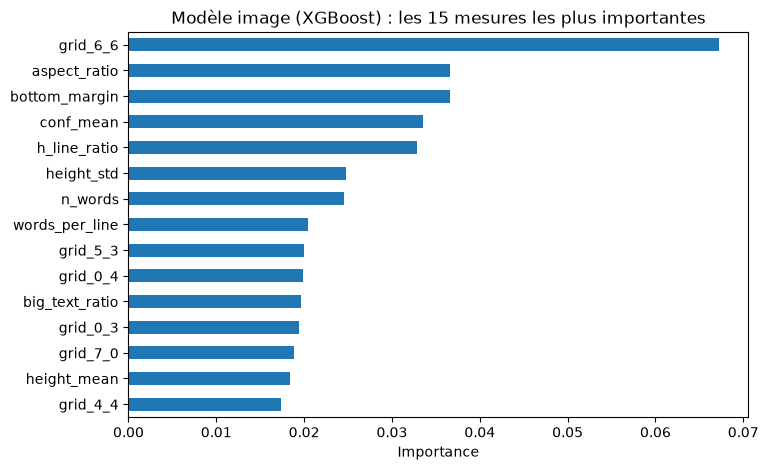

In [5]:
importances = pd.Series(modele.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
importances.sort_values().plot.barh(figsize=(8, 5))
plt.title("Modèle image (XGBoost) : les 15 mesures les plus importantes")
plt.xlabel("Importance")
plt.show()

## 4. Moyenne des mesures importantes, par classe

In [6]:
mesures = ["grid_6_6", "aspect_ratio", "bottom_margin", "conf_mean", "h_line_ratio", "height_std",
           "n_words", "words_per_line", "big_text_ratio", "height_mean"]
X_train.assign(classe=train["label"].values).groupby("classe")[mesures].mean().T.round(3)

classe,email,form,invoice,presentation,resume,scientific_report
grid_6_6,0.007,0.070,0.067,0.067,0.073,0.060
aspect_ratio,0.756,0.767,0.767,0.767,0.757,0.768
bottom_margin,0.380,0.071,0.080,0.104,0.060,0.079
conf_mean,76.932,55.969,48.484,63.529,76.939,63.596
h_line_ratio,0.002,0.018,0.021,0.020,0.006,0.014
height_std,6.255,14.860,14.540,13.714,6.852,11.304
n_words,134.858,204.164,196.137,173.728,345.601,210.341
words_per_line,6.140,5.891,5.756,5.707,7.852,6.156
big_text_ratio,0.079,0.184,0.200,0.114,0.057,0.119
height_mean,21.145,27.193,23.943,31.223,22.486,24.120
